In [92]:
#all the initial libaries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

Data Loading & Inspection

In [93]:
#loading the dataset in df dataframe
df = pd.read_csv("Bank Customer Churn Prediction.csv")

In [94]:
#number of rows and columns
df.shape

(10000, 12)

In [95]:
#first five records
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [96]:
#column names
df.columns

Index(['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure',
       'balance', 'products_number', 'credit_card', 'active_member',
       'estimated_salary', 'churn'],
      dtype='object')

In [97]:
#data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [98]:
#summary of statistics
df.describe()

,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [99]:
#missing and duplicate values
print(df.isnull().sum())
print(df.duplicated().sum())

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64
0


Eda part


/tmp/ipykernel_1426/277167257.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='churn', data=df, palette='Set2')


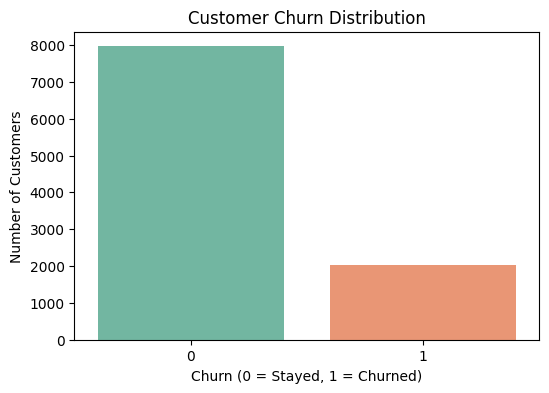

In [100]:
# Target Variable (Churn) ka basic count plot
plt.figure(figsize=(6, 4))
sns.countplot(x='churn', data=df, palette='Set2')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Number of Customers')

plt.show()


Isse kya pata chalega:
Country: Kis country (France, Spain, Germany) ke customers sabse zyada churn kar rahe hain.

Gender: Male vs Female churn rate comparison.

Credit Card / Active Member: Kya active members ya credit card holders bank kam chhodte hain?

Products Number: Kya zyada products use karne wale customers retention par kya asar dalte hain? ↓

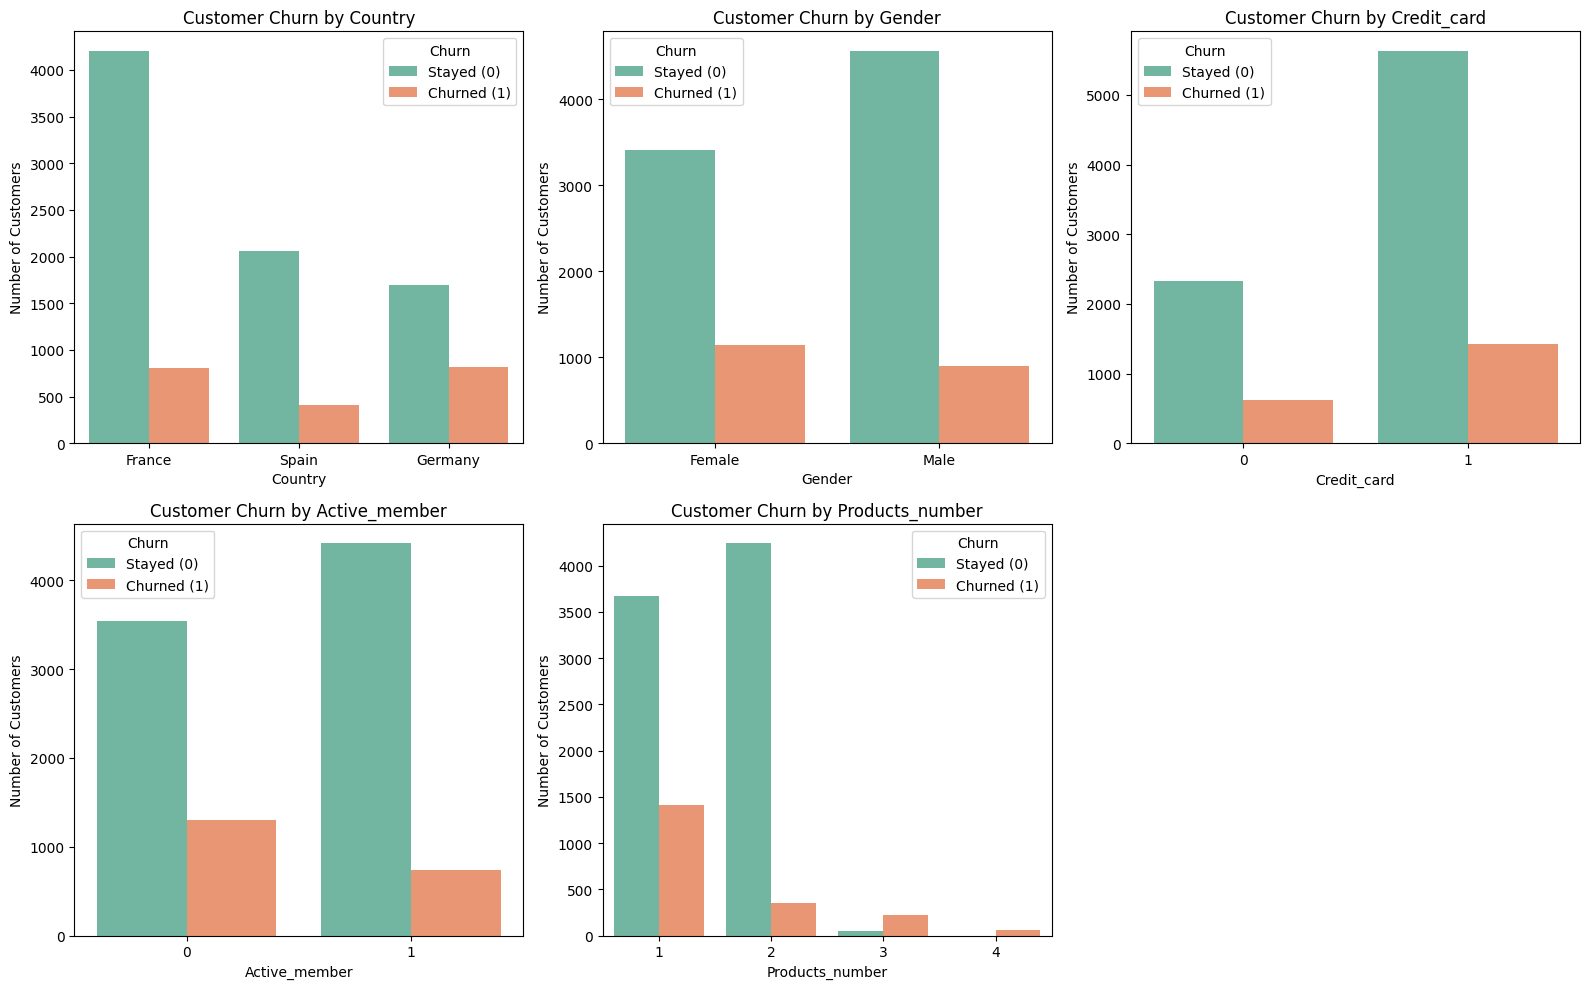

In [101]:
# List of categorical features to plot
cat_features = ['country', 'gender', 'credit_card', 'active_member', 'products_number']

# Subplots create karein (2 rows, 3 cols)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    sns.countplot(x=col, hue='churn', data=df, palette='Set2', ax=axes[i])
    axes[i].set_title(f'Customer Churn by {col.capitalize()}')
    axes[i].set_xlabel(col.capitalize())
    axes[i].set_ylabel('Number of Customers')
    axes[i].legend(title='Churn', labels=['Stayed (0)', 'Churned (1)'])

# Extra empty subplot ko hide karne ke liye
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Isse kya pata chalega:
Age: Aap dekh sakenge ki older customers (e.g., 40–60 years) ka churn rate young customers ke mukable kafi alag/higher trend show karta hai.

Balance: Yeh batayega ki kya high-balance wale customers zyada churn kar rahe hain ya low-balance wale.

Credit Score & Estimated Salary: Inka spread dekh kar pata chalega ki kya financial metrics ka churn par koi direct impact hai ya nahi.↓

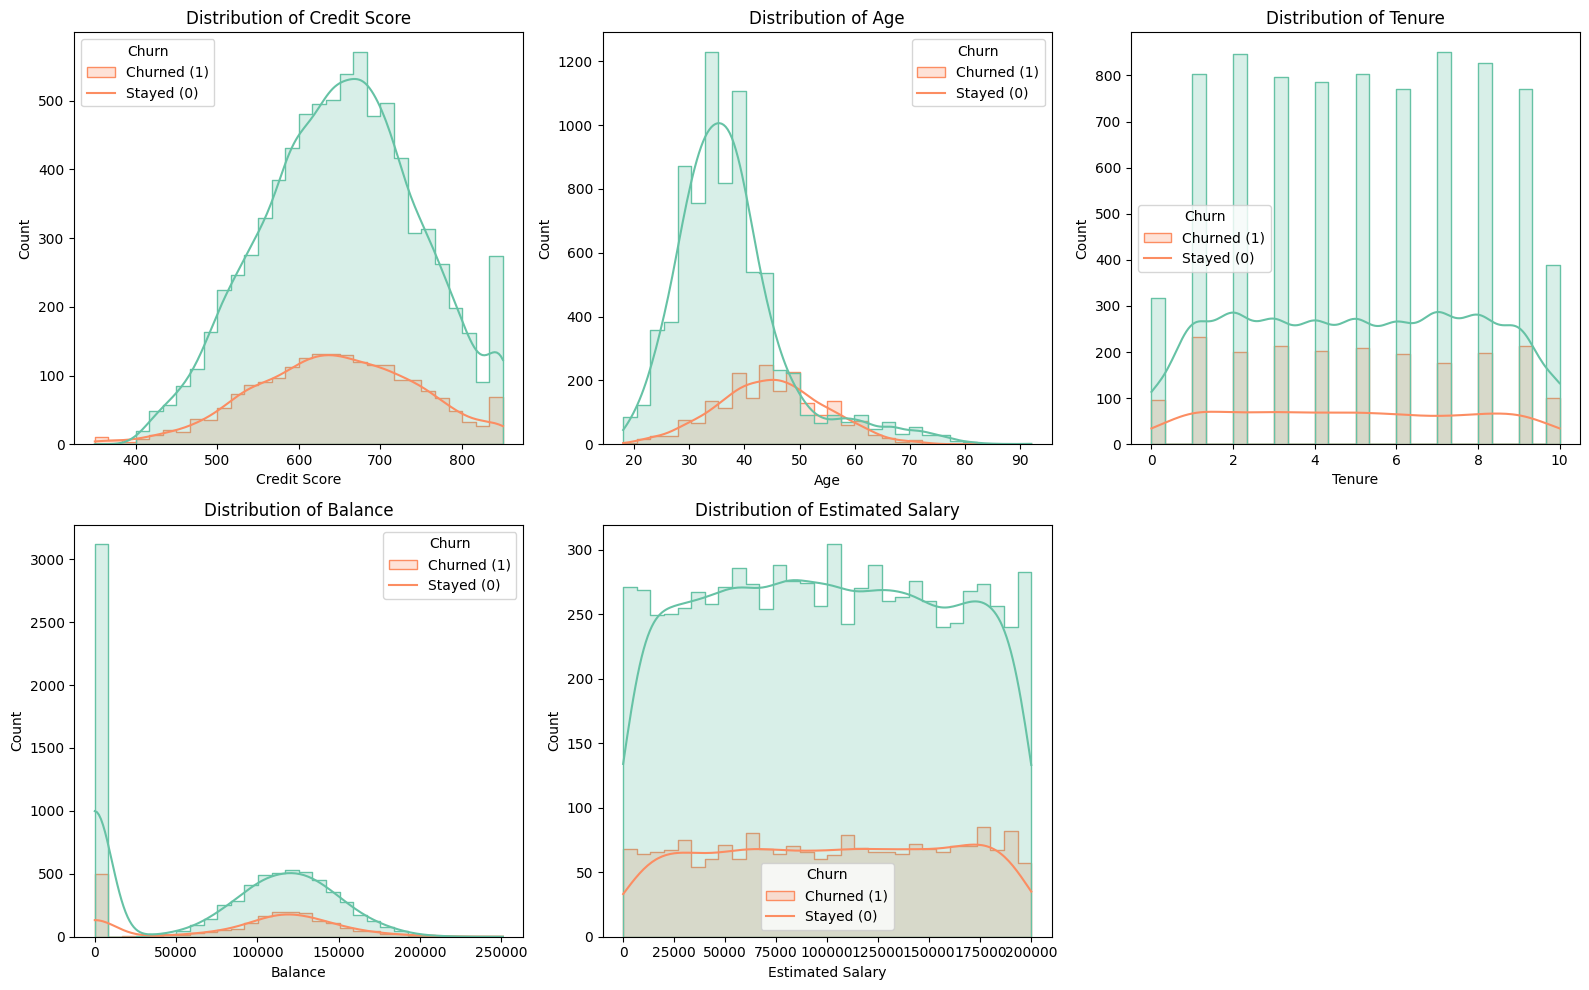

In [102]:
# List of numerical features to plot
num_features = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']

# Subplots create karein (2 rows, 3 cols)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.histplot(data=df, x=col, hue='churn', kde=True, palette='Set2', bins=30, ax=axes[i], element='step')
    axes[i].set_title(f'Distribution of {col.replace("_", " ").title()}')
    axes[i].set_xlabel(col.replace('_', ' ').title())
    axes[i].set_ylabel('Count')
    axes[i].legend(title='Churn', labels=['Churned (1)', 'Stayed (0)'])

# Extra 6th subplot ko hide karne ke liye
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Is analysis se aapko kyainsights milengi :
Country: France mein total customer base sabse zyada hai, lekin Germany ka churn rate (%) baaki countries ke mukable kaafi zyada high hota hai. Yeh point aapki team ke liye bohot valuable hoga!

Active Member: Non-active members (active_member = 0) ka churn rate active members (active_member = 1) se kafi zyada hota hai, jo ye batata hai ki customer engagement kitni zaroori hai.

Products Number: Jin customers ke paas 3 ya 4 products hain, unka churn rate aamtaur par 1 ya 2 products wale customers se alag trend show karta hai.↓

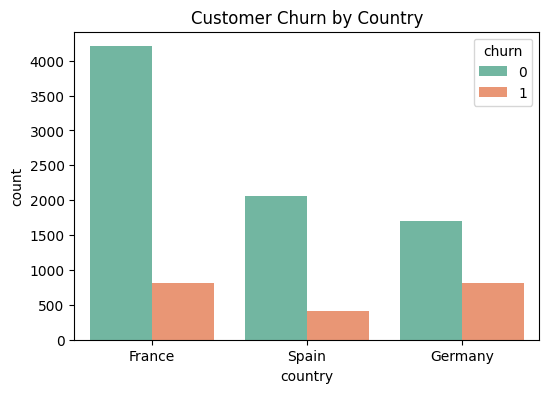

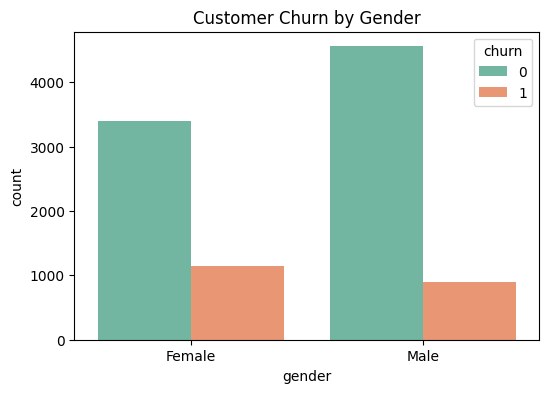

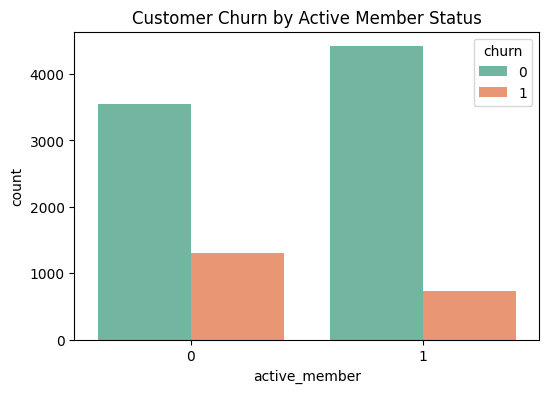

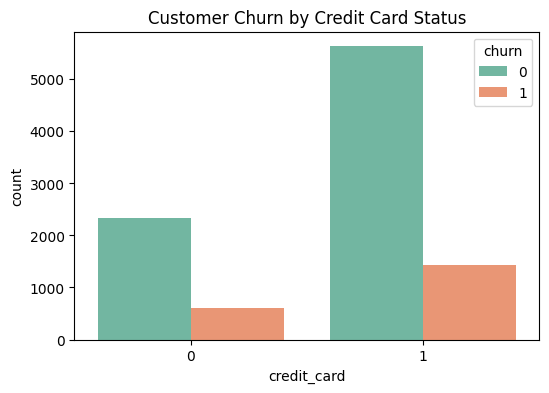

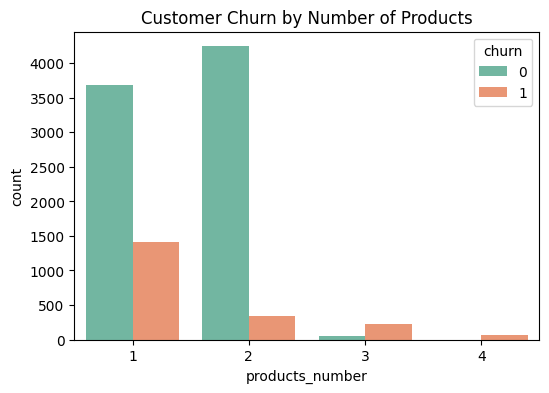

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Country ke liye Count Plot
plt.figure(figsize=(6, 4))
sns.countplot(x='country', hue='churn', data=df, palette='Set2')
plt.title('Customer Churn by Country')
plt.show()

# 2. Gender ke liye Count Plot
plt.figure(figsize=(6, 4))
sns.countplot(x='gender', hue='churn', data=df, palette='Set2')
plt.title('Customer Churn by Gender')
plt.show()

# 3. Active Member ke liye Count Plot
plt.figure(figsize=(6, 4))
sns.countplot(x='active_member', hue='churn', data=df, palette='Set2')
plt.title('Customer Churn by Active Member Status')
plt.show()

# 4. Credit Card ke liye Count Plot
plt.figure(figsize=(6, 4))
sns.countplot(x='credit_card', hue='churn', data=df, palette='Set2')
plt.title('Customer Churn by Credit Card Status')
plt.show()

# 5. Products Number ke liye Count Plot
plt.figure(figsize=(6, 4))
sns.countplot(x='products_number', hue='churn', data=df, palette='Set2')
plt.title('Customer Churn by Number of Products')
plt.show()

yeh sirf numerical features ke beech ka linear relationship dikhata hai. Isse yeh pata nahi chalta ki kaun sa feature model ke liye sabse zyada important (predictive) hai, kyunki machine learning model (jaise hamara SVM) non-linear patterns aur encoded categorical features ko bhi use karta hai!  ↓

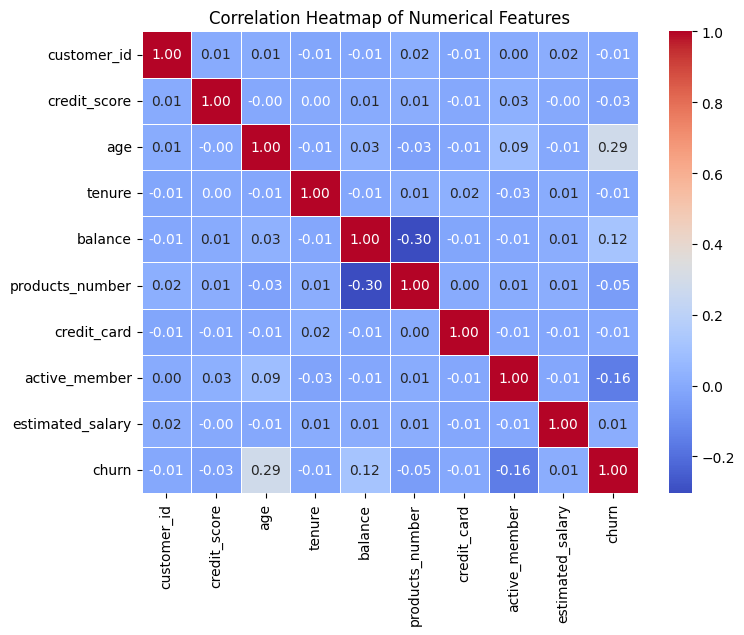

In [104]:
# Sirf numerical columns ke liye correlation matrix banayein
numerical_df = df.select_dtypes(include=['number'])
corr_matrix = numerical_df.corr()

# Heatmap plot karein
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

Age: Is dataset mein max age ~92 years hai, jo ki valid ho sakti hai (older customers ka bank mein hona normal hai), lekin bohot zyada extreme values ko check karna zaroori hota hai.

Balance & Estimated Salary: Balance mein 0.0 values kafi saare customers ki hain (jinne account mein balance nahi rakha), jo ki valid business data hai, data error nahi hai.

Credit Score & Products Number: Inke ranges bhi standard banking domain ke andar hi hain.

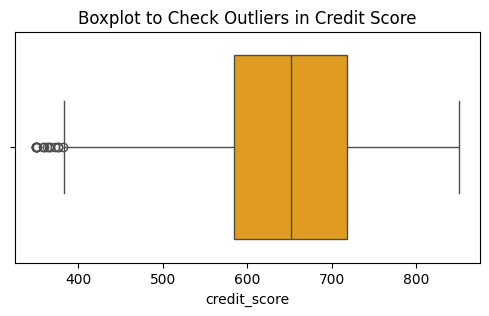

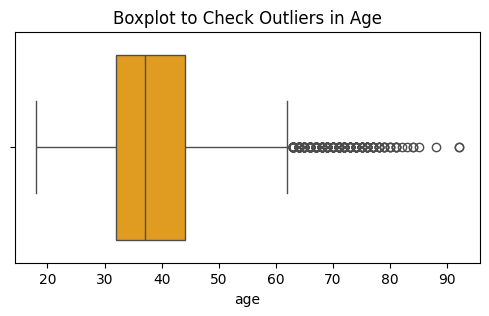

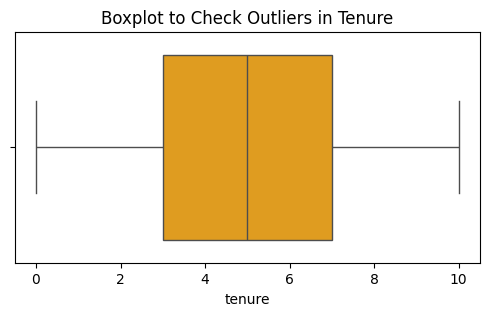

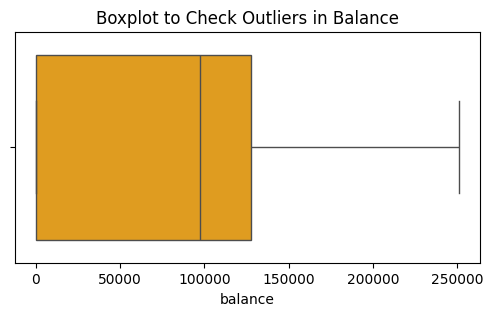

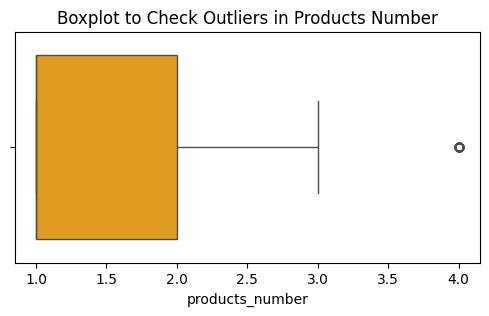

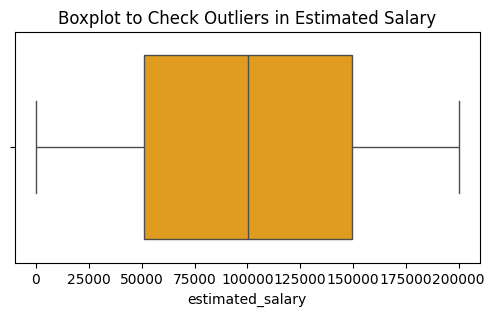

In [105]:
# Outliers check karne ke liye numerical features ki list
outlier_cols = ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary']

# Har column ke liye boxplot banayein
for col in outlier_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col], color='orange')
    plt.title(f'Boxplot to Check Outliers in {col.replace("_", " ").title()}')
    plt.show()

Model training time

In [106]:
#dropping customer_id because it have no meaning in training and churn is our output
x = df.drop(["customer_id","churn"],axis=1)
y = df['churn']

In [107]:
#spliting of data into test and train
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)
"""Code mein stratify=y ka matlab yeh hai ki jab aap apna data train
aur test sets mein divide kar rahe hain, toh y (target/churn column)
ka proportion (percentage) dono sets (train aur test) mein bilkul barabar rahega."""

#spliting of data into test and validation
x_test,x_val,y_test,y_val = train_test_split(
    x_test,
    y_test,
    test_size=0.5,
    random_state=42,
    stratify=y_test
)

In [108]:
#differentating numerical and categorical column
train_num_col = x_train.select_dtypes(include=['number'])
train_cat_col = x_train.select_dtypes(include=['object'])
val_num_col = x_val.select_dtypes(include=['number'])
val_cat_col = x_val.select_dtypes(include=['object'])
test_num_col = x_test.select_dtypes(include=['number'])
test_cat_col = x_test.select_dtypes(include=['object'])

In [109]:
#performing the encoding
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded_train_cat_col = encoder.fit_transform(train_cat_col)
encoded_val_cat_col = encoder.transform(val_cat_col)
encoded_test_cat_col = encoder.transform(test_cat_col)

In [110]:
#performing the scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

scaled_train_num_col = scaler.fit_transform(train_num_col)
scaled_val_num_col = scaler.transform(val_num_col)
scaled_test_num_col = scaler.transform(test_num_col)


In [111]:
# Scaled numerical aur encoded categorical columns ko horizontally jor rahe hain
x_train_final = np.hstack((scaled_train_num_col, encoded_train_cat_col))
x_val_final = np.hstack((scaled_val_num_col, encoded_val_cat_col))
x_test_final = np.hstack((scaled_test_num_col, encoded_test_cat_col))

### model training and Comparing Different SVM Kernels?

SVM (Support Vector Machine) provides different kernels to identify patterns and relationships between input features and the target variable.

In this Bank Customer Churn Prediction dataset, we are comparing four different kernels to understand which one performs better in predicting whether a customer will leave the bank.

We are using the same training and validation datasets for all four kernels to ensure a fair comparison.

**1. Linear Kernel**

- The Linear kernel is used when the data can be separated using a straight decision boundary.
- It is simple and computationally efficient.
- If the relationship between customer features and churn is non-linear, the Linear kernel may not capture complex patterns effectively.
- Therefore, its performance may be lower than non-linear kernels.

**2. RBF (Radial Basis Function) Kernel**

- The RBF kernel is used when the relationship between input features and the target variable is non-linear.
- It can create flexible decision boundaries to identify complex patterns.
- Customer churn may depend on multiple factors, such as age, balance, activity, and product usage.
- The RBF kernel can capture complex relationships between these features.

**3. Polynomial Kernel**

- The Polynomial kernel captures relationships between features using polynomial combinations.
- It can identify more complex patterns than a basic Linear kernel.
- However, its performance depends on the polynomial degree and other hyperparameters.
- If the polynomial degree is not suitable, the model may underfit or overfit.

**4. Sigmoid Kernel**

- The Sigmoid kernel uses a mathematical function similar to the activation function used in neural networks.
- It can capture certain non-linear relationships.
- However, it does not perform equally well on every dataset.
- Its performance depends on the data distribution and parameter settings.




In [112]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Four different SVM kernels
kernels = ['linear', 'rbf', 'poly', 'sigmoid']

results = []

for kernel in kernels:

    # Create model
    model = SVC(
        kernel=kernel,
        C=1.0,
        random_state=42,
        class_weight='balanced'
    )

    # Train on training data
    model.fit(x_train_final, y_train)

    # Predict on validation data
    y_val_pred = model.predict(x_val_final)

    # Calculate validation accuracy
    accuracy = accuracy_score(y_val, y_val_pred)

    # Generate classification report
    report = classification_report(
        y_val,
        y_val_pred,
        output_dict=True
    )

    # Store results
    results.append({
        'Kernel': kernel,
        'Validation Accuracy': accuracy,
        'Precision': report['1']['precision'],
        'Recall': report['1']['recall'],
        'F1 Score': report['1']['f1-score']
    })

    # Print classification report for each kernel
    print(f"\n========== {kernel.upper()} KERNEL ==========")
    print(classification_report(y_val, y_val_pred))

# Compare all kernels
results_df = pd.DataFrame(results)

print("\n========== KERNEL COMPARISON ==========")
print(results_df.round(4).to_string(index=False))


========== LINEAR KERNEL ==========
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1593
           1       0.39      0.71      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000


========== RBF KERNEL ==========
              precision    recall  f1-score   support

           0       0.92      0.80      0.85      1593
           1       0.48      0.73      0.58       407

    accuracy                           0.78      2000
   macro avg       0.70      0.77      0.72      2000
weighted avg       0.83      0.78      0.80      2000


========== POLY KERNEL ==========
              precision    recall  f1-score   support

           0       0.92      0.80      0.86      1593
           1       0.48      0.73      0.58       407

    accuracy                           0.79      2000
   macro avg       0.7

### Analysis of Different SVM Kernels

We tested four different SVM kernels (Linear, RBF, Polynomial, and Sigmoid) using the same training and validation datasets.

The performance of each kernel was evaluated using Accuracy, Precision, Recall, and F1-score for predicting customer churn (Class 1).

**1. Linear Kernel**

- Validation Accuracy: 71.25%
- Precision: 38.71%
- Recall: 70.76%
- F1-score: 50.04%

The Linear kernel achieved the lowest performance among the first three kernels.

This indicates that a simple linear decision boundary may not capture all the relationships between customer features and churn.

Although it identified approximately 71% of actual churn customers, its precision was relatively low. This means that many customers predicted as churn customers were actually non-churn customers.

**2. RBF Kernel**

- Validation Accuracy: 78.35%
- Precision: 47.92%
- Recall: 73.46%
- F1-score: 58.00%

The RBF kernel performed significantly better than the Linear kernel.

RBF can capture non-linear relationships between input features, which may help identify complex customer behaviour patterns.

It achieved a better balance between Precision and Recall for the churn class, resulting in a higher F1-score.

**3. Polynomial Kernel**

- Validation Accuracy: 78.50%
- Precision: 48.14%
- Recall: 72.97%
- F1-score: 58.01%

The Polynomial kernel achieved the highest validation accuracy and F1-score among all four kernels.

It can capture more complex relationships between features using polynomial transformations.

Its performance was very close to the RBF kernel, with slightly better Accuracy, Precision, and F1-score.

**4. Sigmoid Kernel**

- Validation Accuracy: 51.70%
- Precision: 22.02%
- Recall: 54.05%
- F1-score: 31.29%

The Sigmoid kernel performed poorly compared to the other three kernels.

Its low Precision indicates that many of its predicted churn customers were incorrect.

This suggests that the Sigmoid kernel, with the current parameter settings, is not suitable for capturing the patterns in this dataset.

### Final Observation

Based on the validation results, the Polynomial kernel achieved the highest Accuracy (78.50%) and F1-score (58.01%).

The RBF kernel performed almost equally well, with an F1-score of 58.00%.

The Linear kernel showed lower performance, while the Sigmoid kernel produced the weakest results.

Since customer churn prediction requires identifying customers who are likely to leave the bank, Recall and F1-score for Class 1 are important evaluation metrics.

Poly and RBF are almost tied.
- Poly has the highest accuracy and F1-score, but only by a tiny margin.
- RBF has the highest churn recall, meaning it identifies slightly more actual churn customers.
- but our main goal is to identify as many customers likely to leave as possible, RBF wins.

Further experiments with different values of C and gamma are required before selecting the final model.

### Why Are We Performing Hyperparameter Tuning?

After comparing four different SVM kernels, we selected the RBF kernel for further experimentation because it achieved a high Recall and F1-score for the churn class.

However, the performance of an SVM model also depends on its hyperparameters.

Therefore, we are experimenting with different values of C and gamma to find a suitable configuration.

**1. C Parameter**

The C parameter controls the penalty for misclassification.

- A smaller C value allows more classification errors and creates a wider margin.
- A larger C value penalizes classification errors more strongly.
- We are testing 0.1, 1.0, and 10 to understand how C affects model performance.

**2. Gamma Parameter**

Gamma controls the influence of individual training points in the RBF kernel.

- A smaller gamma creates a smoother decision boundary.
- A larger gamma creates a more complex decision boundary.
- We are testing 'scale', 'auto', 0.01, 0.1, and 1.

**3. Model Evaluation**

We are testing 15 different combinations of C and gamma.

Each model is trained using the training dataset and evaluated using the validation dataset.

We compare Accuracy, Precision, Recall, and F1-score. The F1-score of the churn class (Class 1) is used as the primary metric for selecting the best configuration.

The final configuration will be selected based on the validation results.

In [113]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd

# Different values of C and Gamma
c_values = [0.1, 1.0, 10]
gamma_values = ['scale', 'auto', 0.01, 0.1, 1]

results = []

# Test different combinations
for c in c_values:
    for g in gamma_values:

        # Create RBF model
        model = SVC(
            kernel='rbf',
            C=c,
            gamma=g,
            class_weight='balanced',
            random_state=42
        )

        # Train on training data
        model.fit(x_train_final, y_train)

        # Predict on validation data
        y_val_pred = model.predict(x_val_final)

        # Calculate performance metrics
        results.append({
            'C': c,
            'Gamma': g,
            'Accuracy': accuracy_score(y_val, y_val_pred),
            'Precision': precision_score(y_val, y_val_pred, zero_division=0),
            'Recall': recall_score(y_val, y_val_pred, zero_division=0),
            'F1 Score': f1_score(y_val, y_val_pred, zero_division=0)
        })

# Create comparison table
results_df = pd.DataFrame(results)

# Sort according to F1 Score
results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

print("========== RBF HYPERPARAMETER COMPARISON ==========")
print(results_df.round(4).to_string(index=False))

========== RBF HYPERPARAMETER COMPARISON ==========
   C Gamma  Accuracy  Precision  Recall  F1 Score
 1.0  auto    0.7870     0.4848  0.7420    0.5864
10.0  auto    0.7890     0.4877  0.7322    0.5855
 0.1 scale    0.7810     0.4760  0.7543    0.5837
 1.0   0.1    0.7850     0.4815  0.7371    0.5825
 0.1   0.1    0.7800     0.4744  0.7518    0.5817
 1.0 scale    0.7835     0.4792  0.7346    0.5800
10.0  0.01    0.7835     0.4791  0.7322    0.5792
 0.1  auto    0.7775     0.4707  0.7494    0.5782
10.0 scale    0.7825     0.4767  0.7027    0.5680
10.0   0.1    0.7805     0.4736  0.7052    0.5666
 1.0  0.01    0.7610     0.4465  0.7273    0.5533
 0.1  0.01    0.7435     0.4223  0.7076    0.5289
 0.1     1    0.6785     0.3712  0.8354    0.5140
 1.0     1    0.7830     0.4620  0.4029    0.4304
10.0     1    0.7900     0.4767  0.3268    0.3878


### RBF Kernel Hyperparameter Tuning – Result Analysis

In this step, we tested 15 different combinations of **C** and **Gamma** values using the RBF kernel to find the best-performing configuration.

We used the validation dataset to compare the models. The **F1 Score** was selected as the primary evaluation metric because it balances Precision and Recall.

**Best Configuration:**
- C = 1.0
- Gamma = auto
- Accuracy = 78.70%
- Precision = 48.48%
- Recall = 74.20%
- F1 Score = 58.64%

**Observations:**

1. The combination C = 1.0 and Gamma = auto achieved the highest F1 Score of 58.64%.
2. C = 10.0 and Gamma = auto achieved the highest Accuracy of 78.90%, but its F1 Score was slightly lower.
3. C = 0.1 and Gamma = scale achieved the highest Recall of 75.43%, which means it identified the largest proportion of actual churn customers among the tested configurations.
4. Gamma = 1 produced a significant decrease in Recall for C = 1.0 and C = 10.0.

**Conclusion:**

Based on the F1 Score, we selected **C = 1.0 and Gamma = auto** as our best RBF configuration. This model provides a balance between Precision and Recall compared with the other tested configurations.

These results are based on the validation dataset. The final performance will be checked separately using the test dataset.

In [114]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

# Create the final selected RBF model
final_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='auto',
    class_weight='balanced',
    random_state=42
)

# Train using training data
final_model.fit(x_train_final, y_train)

# Predict on test data
y_test_pred = final_model.predict(x_test_final)

# Evaluate final model
print("Final Test Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("\nFinal Classification Report:")
print(classification_report(y_test, y_test_pred))

Final Test Accuracy: 0.793

Final Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.80      0.86      1592
           1       0.50      0.78      0.61       408

    accuracy                           0.79      2000
   macro avg       0.72      0.79      0.73      2000
weighted avg       0.85      0.79      0.81      2000



### Final Model Evaluation – Test Dataset

After selecting the best RBF configuration (C = 1.0 and Gamma = auto) using the validation dataset, we evaluated the final model on the unseen test dataset.

**Final Model Configuration:**
- Kernel = RBF
- C = 1.0
- Gamma = auto
- Class Weight = balanced

**Test Dataset Results:**
- Accuracy = 79.30%
- Churn Precision = 50%
- Churn Recall = 78%
- Churn F1 Score = 61%

**Observations:**

1. The model achieved 79.30% accuracy on the test dataset.
2. Churn Recall of 78% indicates that the model identified approximately 78% of the customers who actually churned.
3. Churn Precision of 50% indicates that approximately half of the customers predicted as churn customers actually churned.
4. The model achieved an F1 Score of 61% for the churn class, showing a balance between Precision and Recall.
5. Test performance was slightly better than validation performance, with no major performance drop.

**Conclusion:**

The final RBF SVM model achieved 79.30% test accuracy and 78% recall for the churn class. It can identify a good proportion of customers who are likely to leave the bank. However, its 50% precision indicates that some customers will be incorrectly flagged as potential churners.

Therefore, the model provides a useful baseline for bank customer churn prediction, but further improvements in precision and F1 Score may be explored.

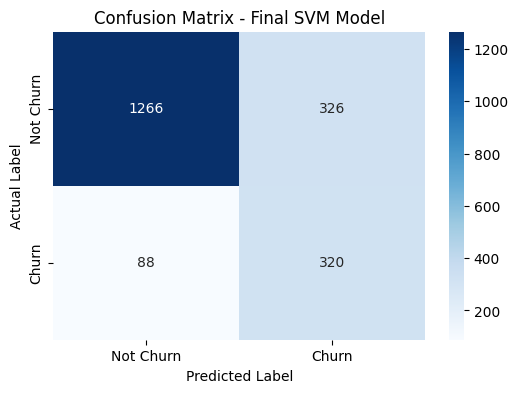

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Plot heatmap
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churn', 'Churn'],
    yticklabels=['Not Churn', 'Churn']
)

plt.title('Confusion Matrix - Final SVM Model')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

ROC-AUC Score: 0.8619


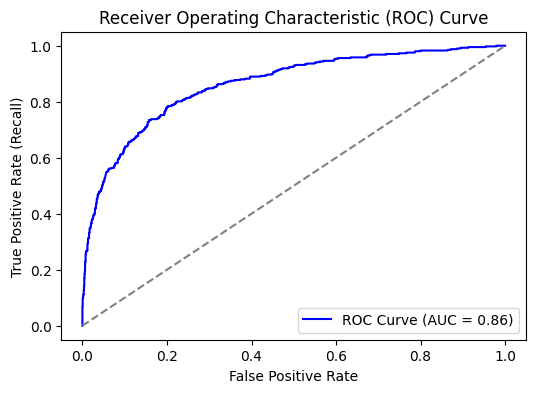

In [116]:
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Probability enable karke model dobara train karein (agar pehle nahi kiya)
svm_model_prob = SVC(kernel='rbf', C=1.0, gamma='auto', probability=True, random_state=42, class_weight='balanced')
svm_model_prob.fit(x_train_final, y_train)

# 2. Probabilities nikaalein (class 1 ke liye)
y_test_prob = svm_model_prob.predict_proba(x_test_final)[:, 1]

# 3. AUC Score calculate karein
auc_score = roc_auc_score(y_test, y_test_prob)
print(f"ROC-AUC Score: {auc_score:.4f}")

# 4. ROC Curve Plot karein
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--') # Diagonal random guess line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

Average Precision Score: 0.6872


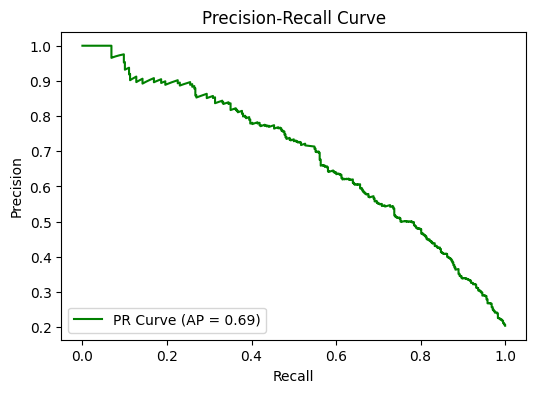

In [117]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Average Precision Score
ap_score = average_precision_score(y_test, y_test_prob)
print(f"Average Precision Score: {ap_score:.4f}")

# Precision-Recall Curve Plot karein
precision, recall, thresholds = precision_recall_curve(y_test, y_test_prob)

plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color='green', label=f'PR Curve (AP = {ap_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.show()

1. ROC Curve & AUC Score (0.8619)
AUC (Area Under the Curve) = 0.86: Yeh score 0.5 (random guess) se kaafi upar hai aur 1.0 (perfect model) ke kafi kareeb hai. Iska matlab hai ki aapka model non-churners (0) aur actual churners (1) ke beech bohot acchi tarah se distinguish (farq) kar pa raha hai.

Graph kya batata hai: X-axis par False Positive Rate hai aur Y-axis par True Positive Rate (Recall) hai. Yeh curve dikhata hai ki jaise-jaise hum threshold change karte hain, model kitne zyada sahi churners ko pakadta hai bina zyada false alarms diye.

The Precision-Recall curve shows the relationship between Precision and Recall at different classification thresholds.

Average Precision (AP) summarizes the Precision-Recall curve into a single score.

Our model achieved an Average Precision score of 0.6872.

This score indicates that the model has a useful ability to rank churn customers above non-churn customers. The Precision-Recall curve is particularly useful when working with an imbalanced dataset, where the number of churn customers is smaller than the number of non-churn customers.

The curve also helps us understand the trade-off between identifying more churn customers and generating false alarms.

### Final Conclusion

In this project, we developed a Bank Customer Churn Prediction model using Support Vector Machine (SVM).

We compared four different SVM kernels and selected the RBF kernel for further experimentation. After testing different values of C and Gamma, we selected C = 1.0 and Gamma = auto based on the highest validation F1 Score.

The final model achieved the following results on the unseen test dataset:

- Accuracy: 79.30%
- Precision (Churn): 50%
- Recall (Churn): 78%
- F1 Score (Churn): 61%
- ROC-AUC Score: 0.8619
- Average Precision Score: 0.6872

The model successfully identifies a good proportion of customers who are likely to leave the bank. However, its precision indicates that some customers are incorrectly classified as potential churners.

Overall, this project demonstrates how machine learning and SVM can be used for customer churn prediction. Further improvements could focus on increasing precision and F1 Score while maintaining good churn recall.